In [ ]:
import re
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from gensim.models import Word2Vec

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout, SpatialDropout1D
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow: 2.21.0
GPU devices: []


In [2]:
from datasets import load_dataset

ds = load_dataset("papluca/language-identification")

In [3]:
ds

DatasetDict({
    train: Dataset({
        features: ['labels', 'text'],
        num_rows: 70000
    })
    validation: Dataset({
        features: ['labels', 'text'],
        num_rows: 10000
    })
    test: Dataset({
        features: ['labels', 'text'],
        num_rows: 10000
    })
})

In [4]:
train_df = ds["train"].to_pandas()
valid_df = ds["validation"].to_pandas()
test_df = ds["test"].to_pandas()

print("Train:", train_df.shape)
print("Validation:", valid_df.shape)
print("Test:", test_df.shape)
print(train_df.head())

Train: (70000, 2)
Validation: (10000, 2)
Test: (10000, 2)
  labels                                               text
0     pt  os chefes de defesa da estónia, letónia, lituâ...
1     bg  размерът на хоризонталната мрежа може да бъде ...
2     zh  很好，以前从不去评价，不知道浪费了多少积分，现在知道积分可以换钱，就要好好评价了，后来我就把...
3     th  สำหรับ ของเก่า ที่ จริงจัง ลอง   honeychurch  ...
4     ru                             Он увеличил давление .


In [ ]:
print(train_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   labels  70000 non-null  str  
 1   text    70000 non-null  str  
dtypes: str(2)
memory usage: 12.3 MB
None


In [5]:
print(train_df.isnull().sum())
print(test_df.isnull().sum())
print(valid_df.isnull().sum())

labels    0
text      0
dtype: int64
labels    0
text      0
dtype: int64
labels    0
text      0
dtype: int64


In [6]:
print("\nNumber of languages:", train_df["labels"].nunique())
print(train_df["labels"].value_counts())


Number of languages: 20
labels
pt    3500
bg    3500
zh    3500
th    3500
ru    3500
pl    3500
ur    3500
sw    3500
tr    3500
es    3500
ar    3500
it    3500
hi    3500
de    3500
el    3500
nl    3500
fr    3500
vi    3500
en    3500
ja    3500
Name: count, dtype: int64


In [7]:
import re

In [15]:
def tokenize_text(text):
    text = str(text).lower()
    return re.findall(r"[^\W\d_]+", text, flags=re.UNICODE)

In [19]:
train_tokens = train_df["text"].apply(tokenize_text)
valid_tokens = valid_df["text"].apply(tokenize_text)
test_tokens = test_df["text"].apply(tokenize_text)

In [20]:
print("Original Text:")
print(train_df["text"].iloc[0])

print("\nProcessed Tokens:")
print(train_df["tokens"].iloc[0])

Original Text:
os chefes de defesa da estónia, letónia, lituânia, alemanha, itália, espanha e eslováquia assinarão o acordo para fornecer pessoal e financiamento para o centro.

Processed Tokens:
['os', 'chefes', 'de', 'defesa', 'da', 'estónia', 'letónia', 'lituânia', 'alemanha', 'itália', 'espanha', 'e', 'eslováquia', 'assinarão', 'o', 'acordo', 'para', 'fornecer', 'pessoal', 'e', 'financiamento', 'para', 'o', 'centro']


In [21]:
tokenizer = Tokenizer(
    num_words=None,
    filters="",
    lower=False,
    split=" "
)

In [22]:
tokenizer.fit_on_texts([" ".join(tokens) for tokens in train_tokens])

In [24]:
vocab_size = len(tokenizer.word_index) + 1

train_texts = [" ".join(tokens) for tokens in train_tokens]
valid_texts = [" ".join(tokens) for tokens in valid_tokens]
test_texts = [" ".join(tokens) for tokens in test_tokens]

In [25]:
X_train_seq = tokenizer.texts_to_sequences(train_texts)
X_valid_seq = tokenizer.texts_to_sequences(valid_texts)
X_test_seq = tokenizer.texts_to_sequences(test_texts)

In [26]:
sequence_lengths = [len(seq) for seq in X_train_seq]
MAX_LEN = int(np.percentile(sequence_lengths, 95))
MAX_LEN = max(20, min(MAX_LEN, 200))

In [27]:
print("Vocabulary size:", vocab_size)
print("95th percentile sequence length:", MAX_LEN)
print("Longest training sequence:", max(sequence_lengths))

Vocabulary size: 184817
95th percentile sequence length: 56
Longest training sequence: 431


In [28]:
X_train_pad = pad_sequences(
    X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)
X_valid_pad = pad_sequences(
    X_valid_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)
X_test_pad = pad_sequences(
    X_test_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

print("Train:", X_train_pad.shape)
print("Validation:", X_valid_pad.shape)
print("Test:", X_test_pad.shape)

Train: (70000, 56)
Validation: (10000, 56)
Test: (10000, 56)


In [29]:
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(train_df["labels"])
y_valid = label_encoder.transform(valid_df["labels"])
y_test = label_encoder.transform(test_df["labels"])

NUM_CLASSES = len(label_encoder.classes_)
print("Languages:", list(label_encoder.classes_))
print("Number of classes:", NUM_CLASSES)

Languages: ['ar', 'bg', 'de', 'el', 'en', 'es', 'fr', 'hi', 'it', 'ja', 'nl', 'pl', 'pt', 'ru', 'sw', 'th', 'tr', 'ur', 'vi', 'zh']
Number of classes: 20


In [30]:
EMBEDDING_DIM = 100

sentences = [tokens for tokens in train_tokens if tokens]

w2v_model = Word2Vec(
    sentences=sentences,
    vector_size=EMBEDDING_DIM,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    negative=5,
    epochs=10,
    seed=SEED
)

print("Word2Vec vocabulary:", len(w2v_model.wv))

Word2Vec vocabulary: 71292


In [31]:
print("Vocabulary Size: ",len(w2v_model.wv))
print(w2v_model.wv.most_similar("me", topn=10))

Vocabulary Size:  71292
[('cable', 0.7002421021461487), ('error', 0.698519766330719), ('han', 0.6856546998023987), ('he', 0.6821553707122803), ('amazon', 0.6721646785736084), ('velcro', 0.6614031791687012), ('cables', 0.6587418913841248), ('wifi', 0.6464505195617676), ('lego', 0.6447950601577759), ('compatible', 0.6437351703643799)]


In [32]:
embedding_matrix = np.zeros((vocab_size, EMBEDDING_DIM), dtype=np.float32)

found_words = 0
for word, index in tokenizer.word_index.items():
    vector = w2v_model.wv.get_vector(word) if word in w2v_model.wv else None
    if vector is not None:
        embedding_matrix[index] = vector
        found_words += 1

print("Embedding matrix:", embedding_matrix.shape)
print("Words with pretrained vectors:", found_words, "/", vocab_size - 1)

Embedding matrix: (184817, 100)
Words with pretrained vectors: 71292 / 184816


In [33]:
model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(
        input_dim=vocab_size,
        output_dim=EMBEDDING_DIM,
        weights=[embedding_matrix],
        mask_zero=True,
        trainable=True
    ),
    SpatialDropout1D(0.2),
    LSTM(128, dropout=0.2, recurrent_dropout=0.0),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 56, 100)        │    18,481,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 56, 100)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       117,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,608,504 (70.99 MB)

 Trainable params: 18,608,504 (70.99 MB)

 Non-trainable params: 0 (0.00 B)

In [34]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-5,
    verbose=1
)

history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_valid_pad, y_valid),
    epochs=30,
    batch_size=128,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 327s 546ms/step - accuracy: 0.9142 - loss: 0.3061 - val_accuracy: 0.9579 - val_loss: 0.2076 - learning_rate: 0.0010
Epoch 2/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 368s 630ms/step - accuracy: 0.9824 - loss: 0.0646 - val_accuracy: 0.9615 - val_loss: 0.1789 - learning_rate: 0.0010
Epoch 3/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 397s 723ms/step - accuracy: 0.9943 - loss: 0.0268 - val_accuracy: 0.9621 - val_loss: 0.1777 - learning_rate: 0.0010
Epoch 4/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 2234s 4s/step - accuracy: 0.9955 - loss: 0.0190 - val_accuracy: 0.9626 - val_loss: 0.1736 - learning_rate: 0.0010
Epoch 5/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 278s 508ms/step - accuracy: 0.9972 - loss: 0.0125 - val_accuracy: 0.9624 - val_loss: 0.1846 - learning_rate: 0.0010
Epoch 6/30
547/547 ━━━━━━━━━━━━━━━━━━━━ 0s 493ms/step - accuracy: 0.9978 - loss: 0.0091
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
547/547 ━━━━━━━━━━━━━━━━━━━━ 325s 510ms/step - accuracy: 0

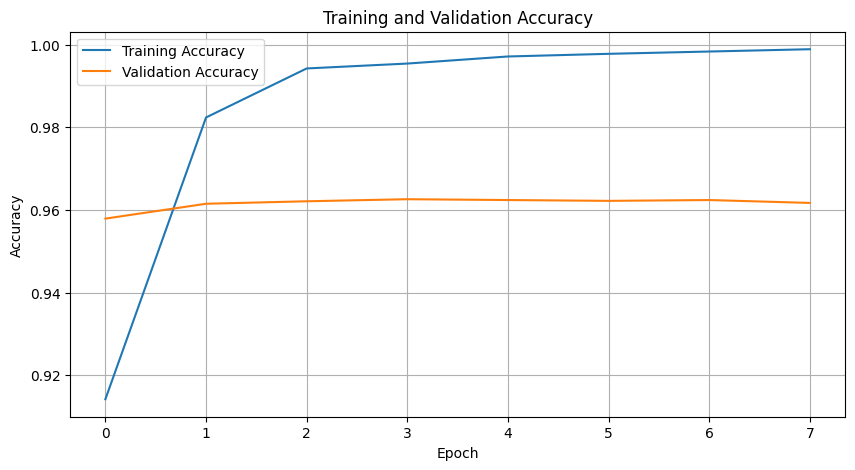

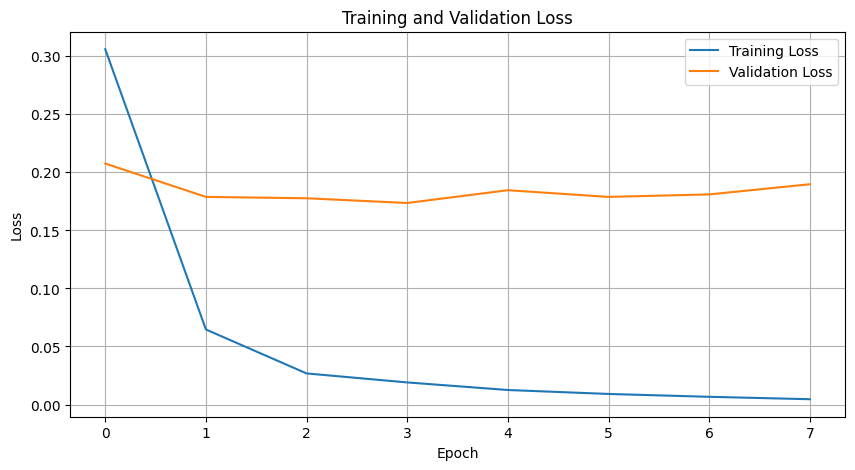

In [35]:
plt.figure(figsize=(10, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")

plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [36]:
train_loss, train_accuracy = model.evaluate(X_train_pad, y_train, batch_size=256, verbose=0)
valid_loss, valid_accuracy = model.evaluate(X_valid_pad, y_valid, batch_size=256, verbose=0)
test_loss, test_accuracy = model.evaluate(X_test_pad, y_test, batch_size=256, verbose=0)

print(f"Training Accuracy:   {train_accuracy * 100:.2f}%")
print(f"Validation Accuracy: {valid_accuracy * 100:.2f}%")
print(f"Testing Accuracy:    {test_accuracy * 100:.2f}%")
print(f"Test Loss:           {test_loss:.4f}")

Training Accuracy:   99.77%
Validation Accuracy: 96.26%
Testing Accuracy:    95.79%
Test Loss:           0.1764


In [38]:
def predict_language(sentence):
    tokens = tokenize_text(sentence)
    text = " ".join(tokens)

    sequence = tokenizer.texts_to_sequences([text])
    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    probabilities = model.predict(padded, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    predicted_language = label_encoder.inverse_transform([predicted_index])[0]
    confidence = float(probabilities[predicted_index]) * 100

    print("Input:", sentence)
    print("Predicted language:", predicted_language)
    print(f"Model confidence: {confidence:.2f}%")

    return predicted_language, confidence

predict_language("I love machine learning and artificial intelligence")
predict_language("Bonjour, comment allez-vous aujourd'hui?")
predict_language("مجھے مشین لرننگ سیکھنا پسند ہے")
predict_language("मैं मशीन लर्निंग सीखना चाहता हूँ")

Input: I love machine learning and artificial intelligence
Predicted language: en
Model confidence: 98.29%
Input: Bonjour, comment allez-vous aujourd'hui?
Predicted language: fr
Model confidence: 100.00%
Input: مجھے مشین لرننگ سیکھنا پسند ہے
Predicted language: ur
Model confidence: 100.00%
Input: मैं मशीन लर्निंग सीखना चाहता हूँ
Predicted language: hi
Model confidence: 100.00%


('hi', 99.99998807907104)

In [37]:
model.save("Language_Identification_LSTM.keras")

with open("language_objects.pkl", "wb") as f:
    pickle.dump(
        {
            "tokenizer": tokenizer,
            "label_encoder": label_encoder,
            "max_len": MAX_LEN,
            "embedding_dim": EMBEDDING_DIM
        },
        f
    )

w2v_model.save("language_word2vec.model")

print("Model and preprocessing objects saved successfully.")

Model and preprocessing objects saved successfully.


In [2]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [3]:
model=load_model('Language_Identification_LSTM.keras')

In [5]:
import pickle

In [7]:
with open("language_objects.pkl","rb") as file:
    objects=pickle.load(file)

In [8]:
tokenizer = objects["tokenizer"]
label_encoder = objects["label_encoder"]
MAX_LEN = objects["max_len"]

In [14]:
import re
import numpy as np

In [27]:
LANGUAGE_NAMES = {
    "ar": "Arabic",
    "bg": "Bulgarian",
    "de": "German",
    "el": "Greek",
    "en": "English",
    "es": "Spanish",
    "fr": "French",
    "hi": "Hindi",
    "it": "Italian",
    "ja": "Japanese",
    "nl": "Dutch",
    "pl": "Polish",
    "pt": "Portuguese",
    "ru": "Russian",
    "sw": "Swahili",
    "th": "Thai",
    "tr": "Turkish",
    "ur": "Urdu",
    "vi": "Vietnamese",
    "zh": "Chinese",
}

In [28]:
def tokenize_text(text):
    text = str(text).lower()
    return re.findall(r"[^\W\d_]+", text, flags=re.UNICODE)

def predict_language(sentence,top_k=3):
    tokens = tokenize_text(sentence)
    sequence=tokenizer.texts_to_sequences([tokens])
    padded=pad_sequences(sequence,maxlen=MAX_LEN,padding="post",truncating="post")
    prob=model.predict(padded,verbose=0)[0]
    print("Input:", sentence)
    predict_index=int(np.argmax(prob))
    language_code=label_encoder.inverse_transform([predict_index])[0]
    predict_language=LANGUAGE_NAMES.get(str(language_code),str(language_code))
    confidence=(prob[predict_index])*100
    print("Predicted language:", predict_language)
    print(f"Model confidence: {confidence:.2f}%")
    return predict_language, confidence
    


In [29]:
predict_language("Sabahları bir fincan sıcak")
predict_language("Buổi sáng tôi thích uống một ly")
predict_language("早上我喜欢喝一杯")

Input: Sabahları bir fincan sıcak
Predicted language: Turkish
Model confidence: 99.99%
Input: Buổi sáng tôi thích uống một ly
Predicted language: Vietnamese
Model confidence: 100.00%
Input: 早上我喜欢喝一杯
Predicted language: Japanese
Model confidence: 26.44%


('Japanese', np.float32(26.436653))

In [31]:
predict_language("Por la mañana me gusta beber")

Input: Por la mañana me gusta beber
Predicted language: Spanish
Model confidence: 100.00%


('Spanish', np.float32(99.99615))